In [1]:
# Import Packages & Load Dataset
# We use the Titanic dataset because it contains numerical values, text, missing records, and categories.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Load dataset directly from source
url = (
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
)
df = pd.read_csv(url)

# Preview first 5 rows
print("Dimensions:", df.shape)
df.head()

Dimensions: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
# Inspect Missing Values And Data Types
# Before changing anything, evaluate data hygiene: how many columns exist, what types they are, and which have missing values

#Check Schema and non-null counts
print("=== INFO ===")
df.info()

#Count null values per column
print("\n === MISSING VALUES ===")
print(df.isnull().sum())

=== INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

 === MISSING VALUES ===
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          6

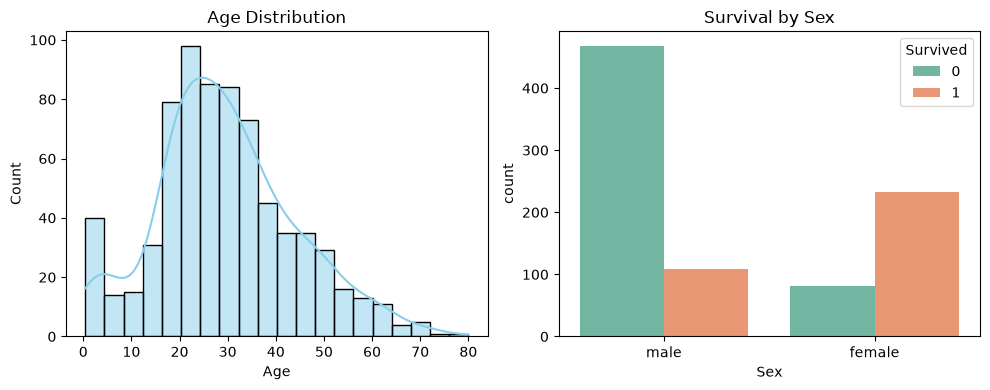

In [3]:
# Exploratory Data Analysis (EDA) Visualizations
# Visualizing distributions and relationships before clearing data
plt.figure(figsize=(10,4))

# 1. Distribution of Age
plt.subplot(1,2,1)
sns.histplot(df["Age"].dropna(), kde=True, color="skyblue")
plt.title("Age Distribution")

# 2. Survival count by Gender
plt.subplot(1,2,2)
sns.countplot(data=df, x="Sex", hue="Survived", palette="Set2")
plt.title("Survival by Sex")

plt.tight_layout()
plt.show()

In [4]:
# Clean Data and Handle Missing Values
# Drop Cabin (too many nulls to infer reliably) and identifiers like PassengerId, Name, Ticket (they do not generalize)
# Impute Age using the median (median is robust against outliers/skewness)
# Impute Embarked using the mode (most frequent departure port)

# Drop non-predictive or heavily missing columns
df_clean = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

# Fill missing numerical values with median
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())

# Fill missing categorical values with mode
df_clean["Embarked"] = df_clean["Embarked"].fillna(
    df_clean["Embarked"].mode()[0]
)

# Confirm zero missing values remain
print("Remaining null values:")
print(df_clean.isnull().sum())

Remaining null values:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [5]:
# Encode Categorical Features
# Machine learning models cannot process plain text like "male" or "Southampton". One-Hot Encoding creates binary columns (0 or 1). We set drop_first=True to remove the redundant column and prevent collinearity

# One-hot encode 'Sex' and 'Embarked'
df_encoded = pd.get_dummies(
    df_clean, columns=["Sex", "Embarked"], drop_first=True, dtype=int
)

print("Columns after encoding:")
print(df_encoded.columns.tolist())
df_encoded.head()

Columns after encoding:
['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


In [6]:
# Feature Scaling and Export
# Fare ranges from 0 to 500+, while Age ranges from 0 to 80. If left unscaled, models can prioritize Fare simply due to magnitude. StandardScaler standardizes features to a mean of 0 and variance of 1

scaler = StandardScaler()
features_to_scale = ["Age", "Fare"]

# Create a copy and scale target columns
df_scaled = df_encoded.copy()
df_scaled[features_to_scale] = scaler.fit_transform(
    df_encoded[features_to_scale]
)

# Save the final cleaned dataset locally
df_scaled.to_csv("titanic_cleaned.csv", index=False)
print("Preprocessing complete. Final shape:", df_scaled.shape)
df_scaled.head()

Preprocessing complete. Final shape: (891, 9)


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,-0.565736,1,0,-0.502445,1,0,1
1,1,1,0.663861,1,0,0.786845,0,0,0
2,1,3,-0.258337,0,0,-0.488854,0,0,1
3,1,1,0.433312,1,0,0.420730,0,0,1
4,0,3,0.433312,0,0,-0.486337,1,0,1
